In [19]:
!pip install ultralytics opencv-python matplotlib pyyaml kagglehub

In [20]:
from ultralytics import YOLO
import os
import yaml
import cv2
import matplotlib.pyplot as plt
import glob
import kagglehub
from pathlib import Path
import zipfile
import shutil
import tempfile

In [21]:
path = kagglehub.dataset_download("fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset")
print("Path to dataset files:", path)
dataset = os.path.join(path, "Visual Pollution Dataset")

Path to dataset files: /kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset


In [22]:
crops_input = Path("/kaggle/input/datasets/muhannadalshamrani/crops/crops")

crop_names = [p.relative_to(crops_input) for p in crops_input.rglob("*.jpg")]
print("Cleaned crops:", len(crop_names))

Cleaned crops: 39547


In [23]:
class_names = ["barriers", "sidewalks", "pothole"]
photos = {}
for crop in crop_names:
    split, label = crop.parts[-3:-1]
    stem, index = crop.stem.rsplit("_", 1)
    if split not in ("train", "val", "test") or label not in class_names:
        raise ValueError(f"Unexpected crop path: {crop}")
    photo = photos.setdefault(stem, {"split": split, "boxes": {}})
    index = int(index)
    if photo["split"] != split or index in photo["boxes"]:
        raise ValueError(f"Conflicting entries for {crop}")
    photo["boxes"][index] = class_names.index(label)

In [24]:
def iou(a, b):
    ax1, ay1, ax2, ay2 = a[0] - a[2] / 2, a[1] - a[3] / 2, a[0] + a[2] / 2, a[1] + a[3] / 2
    bx1, by1, bx2, by2 = b[0] - b[2] / 2, b[1] - b[3] / 2, b[0] + b[2] / 2, b[1] + b[3] / 2
    inter = max(0, min(ax2, bx2) - max(ax1, bx1)) * max(0, min(ay2, by2) - max(ay1, by1))
    union = a[2] * a[3] + b[2] * b[3] - inter
    return inter / union

used kaggle notebook since the dataset is large to download and train on google colab

Using the train, validation and test folders from the cleaned crops.

In [25]:
# The crop index was assigned after the preparation notebook removed conflicting boxes.
source_images = {}
for folder in ("train", "val"):
    for image in (Path(dataset) / "images" / folder).glob("*.jpg"):
        source_images.setdefault(image.stem, []).append(image)

clean_dir = Path(tempfile.mkdtemp(prefix="road_yolo_", dir=".")).resolve()
for split in ("train", "val", "test"):
    (clean_dir / "images" / split).mkdir(parents=True)
    (clean_dir / "labels" / split).mkdir(parents=True)

for stem, photo in photos.items():
    candidates = source_images.get(stem, [])
    if len(candidates) > 1:
        first = candidates[0]
        first_label = Path(dataset) / "labels" / first.parent.name / (stem + ".txt")
        for other in candidates[1:]:
            other_label = Path(dataset) / "labels" / other.parent.name / (stem + ".txt")
            if first.read_bytes() != other.read_bytes() or first_label.read_text().split() != other_label.read_text().split():
                raise ValueError(f"Ambiguous original photo: {stem}")
    if not candidates:
        raise FileNotFoundError(f"Missing original photo: {stem}")
    image = candidates[0]
    label_file = Path(dataset) / "labels" / image.parent.name / (stem + ".txt")
    rows = [line.split() for line in label_file.read_text().splitlines() if line.strip()]
    boxes = [(int(row[0]), *map(float, row[1:])) for row in rows]
    kept = [row for row, box in zip(rows, boxes)
            if not any(box[0] != other[0] and iou(box[1:], other[1:]) > 0.7 for other in boxes)]

    lines = []
    for index, class_id in sorted(photo["boxes"].items()):
        if index >= len(kept) or int(kept[index][0]) != class_id:
            raise ValueError(f"Crop and original label disagree: {stem}_{index}")
        lines.append(" ".join(kept[index]))

    split = photo["split"]
    target = clean_dir / "images" / split / image.name
    target.symlink_to(image.resolve())
    (clean_dir / "labels" / split / label_file.name).write_text("\n".join(lines) + "\n")

for split in ("train", "val", "test"):
    print(split, len(list((clean_dir / "images" / split).glob("*.jpg"))), "full images")

train 21311 full images
val 4542 full images
test 4544 full images


creating a list of the images within the test since it only contained the paths of the images

In [26]:
test_img = sorted(glob.glob(str(clean_dir / "images" / "test" / "*.jpg")))

creating our new yaml

In [27]:
data_yaml = {
    "path": str(clean_dir),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 3,
    "names": class_names
}

In [28]:
yaml_path = str(clean_dir / "data.yaml")
with open(yaml_path, "w") as f:
    yaml.safe_dump(data_yaml, f, sort_keys=False)

In [29]:
with open(yaml_path, "r") as f:
    data_yaml = yaml.safe_load(f)

data_yaml

{'path': '/kaggle/working/road_yolo_s8azke1a',
 'train': 'images/train',
 'val': 'images/val',
 'test': 'images/test',
 'nc': 3,
 'names': ['barriers', 'sidewalks', 'pothole']}

In [30]:
model = YOLO("yolov8n.pt")

Ultralytics has early stopping built in through patience
making patience=5 will allow YOLO to add 5 epochs to beat its best validation score if after 5 epochs score didnt improve training stops
though keep in mind we made it 5 because it less time to execute though we can do 10 for a better improvement

In [31]:
res = model.train(data=yaml_path, epochs=30, imgsz=640, batch=100,patience=5)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=100, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/road_yolo_s8azke1a/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=None, opti

In [32]:
val = model.val()

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 196.2±37.9 MB/s, size: 103.7 KB)
val: Scanning /kaggle/working/road_yolo_s8azke1a/labels/val.cache... 4542 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4542/4542 1.4Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 284/284 8.1it/s 34.9s0.1ss
                   all       4542       5793      0.627      0.623      0.657      0.429
              barriers        905       1151      0.602        0.6      0.624      0.446
             sidewalks        865        944      0.572      0.577      0.588      0.341
               pothole       3107       3698      0.705      0.691      0.759        0.5
Speed: 0.7ms preprocess, 3.2ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /kaggle/worki

In [41]:
print(val)

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x78ebd4b26c80>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

In [42]:
print(f"Precision: {val.box.mp:.2%}")
print(f"Recall: {val.box.mr:.2%}")
print(f"mAP50: {val.box.map50:.2%}")
print(f"mAP50-95: {val.box.map:.2%}")

Precision: 62.65%
Recall: 62.30%
mAP50: 65.71%
mAP50-95: 42.90%


In [43]:
test = test_img[0]
res2 = model.predict(test)


image 1/1 /kaggle/working/road_yolo_s8azke1a/images/test/DATA-WORKATTACH-FILE MOMRA-OPS-CS-WORK INC-21-07-051970!20210718T214203.221 GMT.jpg: 640x512 1 pothole, 11.0ms
Speed: 2.4ms preprocess, 11.0ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 512)


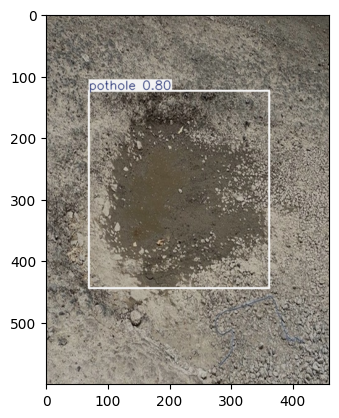

In [44]:
plt.imshow(cv2.cvtColor(res2[0].plot(), cv2.COLOR_BGR2RGB))

In [ ]:
test_results = model.val(data=yaml_path, split="test")
print("Test results")
print(f"Precision: {test_results.box.mp:.2%}")
print(f"Recall: {test_results.box.mr:.2%}")
print(f"mAP50: {test_results.box.map50:.2%}")
print(f"mAP50-95: {test_results.box.map:.2%}")

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.4±0.1 ms, read: 1.5±0.6 MB/s, size: 101.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/working/road_yolo_s8azke1a/labels/test... 4544 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4544/4544 37.9it/s 2:000.0ssss
val: New cache created: /kaggle/working/road_yolo_s8azke1a/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 284/284 7.8it/s 36.4s0.1ss
                   all       4544       5871      0.623      0.625      0.651      0.424
              barriers        905       1204      0.584      0.605      0.598      0.427
             sidewalks        889        974      0.593    

In [ ]:
test = test_img[1]
res2 = model.predict(test)


image 1/1 /kaggle/working/road_yolo_s8azke1a/images/test/DATA-WORKATTACH-FILE MOMRA-OPS-CS-WORK INC-21-07-051970!20210718T214204.572 GMT.jpg: 640x512 1 pothole, 13.3ms
Speed: 2.1ms preprocess, 13.3ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 512)


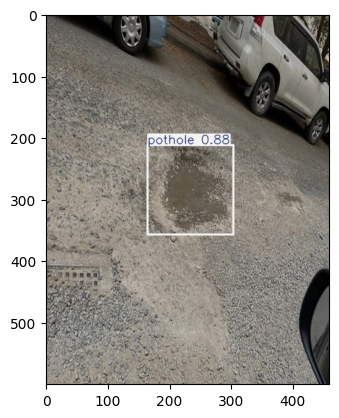

In [ ]:
plt.imshow(cv2.cvtColor(res2[0].plot(), cv2.COLOR_BGR2RGB))

exporting model

In [ ]:
model.export(format="onnx")

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from '/kaggle/working/runs/detect/train-2/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (6.2 MB)
requirements: Ultralytics requirements ['onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
WARNING ⚠️ Retry 1/2 failed: Command '['uv', 'pip', 'install', '--no-cache-dir', '--python', '/usr/bin/python3', 'onnxruntime', 'onnxslim>=0.1.82', '--index-strategy=unsafe-best-match', '--break-system-packages']' returned non-zero exit status 2.
WARNING ⚠️ Retry 2/2 failed: Command '['uv', 'pip', 'install', '--no-cache-dir', '--python', '/usr/bin/python3', 'onnxruntime', 'onnxslim>=0.1.82', '--index-strategy=unsafe-be

'/kaggle/working/runs/detect/train-2/weights/best.onnx'